# Sri Lanka Landslide Susceptibility — Full Pipeline
Consolidated notebook: rainfall enrichment → cleaning → feature engineering → modeling → evaluation → hybrid models.

**Run order matters** — if you edit an early cell, use *Restart Kernel and Run All* rather than re-running cells out of order, to avoid stale-variable errors.

## 0. Setup
Paths and imports used throughout the notebook.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
from shapely.geometry import Point

DATA_RAW = Path("../data/raw/")
DATA_PROCESSED = Path("../data/processed")
DATA_RAW.mkdir(parents=True, exist_ok=True)
DATA_PROCESSED.mkdir(parents=True, exist_ok=True)

## 2. Load enriched data & clean

In [3]:
df = pd.read_csv(DATA_PROCESSED / "training_table_with_rainfall.csv")
print(df.shape)
print(df["label"].value_counts())
df.isna().sum()

(1463, 22)
label
1    732
0    731
Name: count, dtype: int64


label               0
country             0
source_dataset      0
district            0
slope               0
aspect              0
twi                 0
spi                 0
dist_to_river       0
dist_to_road        0
elev                0
plan_curv           0
profile_curv        0
x                   0
y                   0
longitude           0
latitude            0
rain_1d           112
rain_3d           112
rain_7d           112
rain_15d          112
rain_30d          112
dtype: int64

In [4]:
# Fill any remaining null rainfall values via spatial nearest-neighbor
# (these are timeout gaps, not real missing data -- the location has rainfall,
# the API call just failed, so borrow from the closest point that succeeded)
from sklearn.neighbors import BallTree

rain_cols = ["rain_1d", "rain_3d", "rain_7d", "rain_15d", "rain_30d"]
valid = df.dropna(subset=rain_cols)
missing = df[df[rain_cols].isna().any(axis=1)]

if len(missing):
    tree = BallTree(np.radians(valid[["latitude", "longitude"]]), metric="haversine")
    _, idx = tree.query(np.radians(missing[["latitude", "longitude"]]), k=1)
    nearest_vals = valid.iloc[idx.flatten()][rain_cols].reset_index(drop=True)
    df.loc[missing.index, rain_cols] = nearest_vals.values

print(f"Remaining nulls: {df[rain_cols].isna().sum().sum()}")

Remaining nulls: 0


## 3. Feature engineering
Rainfall proportion features and terrain interaction/ratio features, built on top of the cleaned columns.

In [5]:
eng = df.copy()

# --- Rainfall proportion / timing features ---
eng["rain_burst_ratio"] = eng["rain_1d"] / eng["rain_30d"].replace(0, np.nan)
eng["rain_delta_1_3"] = eng["rain_3d"] - eng["rain_1d"]
eng["rain_delta_3_7"] = eng["rain_7d"] - eng["rain_3d"]
eng["rain_delta_7_15"] = eng["rain_15d"] - eng["rain_7d"]

district_avg = eng.groupby("district")["rain_30d"].transform("mean")
eng["rain_30d_anomaly"] = eng["rain_30d"] / district_avg

# --- Terrain ratio / interaction features ---
eng["slope_elev_ratio"] = eng["slope"] / eng["elev"].replace(0, np.nan)
eng["curv_product"] = eng["plan_curv"] * eng["profile_curv"]
eng["river_road_ratio"] = eng["dist_to_river"] / eng["dist_to_road"].replace(0, np.nan)
eng["twi_spi_ratio"] = eng["twi"] / eng["spi"].replace(0, np.nan)

new_feature_cols = ["rain_burst_ratio", "rain_delta_1_3", "rain_delta_3_7", "rain_delta_7_15",
                     "rain_30d_anomaly", "slope_elev_ratio", "curv_product",
                     "river_road_ratio", "twi_spi_ratio"]
eng[new_feature_cols] = eng[new_feature_cols].replace([np.inf, -np.inf], np.nan)
eng[new_feature_cols] = eng[new_feature_cols].fillna(eng[new_feature_cols].median())

eng[new_feature_cols].describe()

,rain_burst_ratio,rain_delta_1_3,rain_delta_3_7,rain_delta_7_15,rain_30d_anomaly,slope_elev_ratio,curv_product,river_road_ratio,twi_spi_ratio
count,1463.000000,1463.000000,1463.000000,1463.000000,1463.000000,1.463000e+03,1.463000e+03,1463.000000,1463.000000
mean,0.000284,1.014286,451.528982,177.127273,1.000000,2.759282e-02,8.801646e-06,10.213623,1140.962663
std,0.000809,1.076713,130.907947,32.445896,0.143137,3.208019e-02,4.974106e-05,18.465046,19189.550530
min,0.000000,0.000000,175.700000,106.300000,0.673271,3.292482e-07,-1.564705e-04,0.000000,-0.363290
25%,0.000000,0.100000,371.100000,154.400000,0.885320,1.009798e-02,-1.620056e-06,1.481493,0.784625
50%,0.000000,0.800000,436.800000,168.300000,0.996584,1.879373e-02,9.548575e-07,3.610877,1.969743
75%,0.000215,1.500000,564.500000,196.700000,1.108529,3.355456e-02,7.510771e-06,9.566215,5.386169
max,0.006241,8.300000,749.600000,258.300000,1.314736,4.062226e-01,1.365657e-03,182.386942,552681.250740


## 4. Build model matrix
Drop redundant/non-predictive columns, one-hot encode district, keep lat/lon aside (used only for spatial grouping, not as features).

In [6]:
drop_cols = ["country", "x", "y", "source_dataset"]
model_df = eng.drop(columns=drop_cols)
model_df = pd.get_dummies(model_df, columns=["district"], drop_first=True)

feature_cols = [c for c in model_df.columns if c not in ["label", "longitude", "latitude"]]
X = model_df[feature_cols]
y = model_df["label"]
groups = eng["district"]   # used only for spatial splitting, not as a feature

print(f"{X.shape[1]} features, {len(y)} rows")
feature_cols

26 features, 1463 rows


['slope',
 'aspect',
 'twi',
 'spi',
 'dist_to_river',
 'dist_to_road',
 'elev',
 'plan_curv',
 'profile_curv',
 'rain_1d',
 'rain_3d',
 'rain_7d',
 'rain_15d',
 'rain_30d',
 'rain_burst_ratio',
 'rain_delta_1_3',
 'rain_delta_3_7',
 'rain_delta_7_15',
 'rain_30d_anomaly',
 'slope_elev_ratio',
 'curv_product',
 'river_road_ratio',
 'twi_spi_ratio',
 'district_Kandy',
 'district_Kegalle',
 'district_Nuwara Eliya']

## 5. Train/test split by district (avoids spatial leakage)

In [7]:
from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(test_size=0.25, n_splits=1, random_state=42)
train_idx, test_idx = next(splitter.split(X, y, groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

print("Train districts:", groups.iloc[train_idx].unique())
print("Test districts:", groups.iloc[test_idx].unique())

Train districts: ['Nuwara Eliya' 'Kegalle' 'Badulla']
Test districts: ['Kandy']


## 6. Baseline models

In [8]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

# --- Random Forest (depth-limited to reduce overfitting on small district groups) ---
rf = RandomForestClassifier(n_estimators=300, max_depth=8, min_samples_leaf=15,
                             random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
pred_rf = rf.predict(X_test)
proba_rf = rf.predict_proba(X_test)[:, 1]

print("=== Random Forest ===")
print(classification_report(y_test, pred_rf))
print("ROC-AUC:", roc_auc_score(y_test, proba_rf))
print(confusion_matrix(y_test, pred_rf))

=== Random Forest ===
              precision    recall  f1-score   support

           0       0.55      0.73      0.63       288
           1       0.61      0.41      0.49       289

    accuracy                           0.57       577
   macro avg       0.58      0.57      0.56       577
weighted avg       0.58      0.57      0.56       577

ROC-AUC: 0.6816248558246827
[[211  77]
 [171 118]]


In [9]:
# --- Logistic Regression (needs scaling) ---
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

logreg = LogisticRegression(max_iter=1000)
logreg.fit(X_train_scaled, y_train)
pred_lr = logreg.predict(X_test_scaled)
proba_lr = logreg.predict_proba(X_test_scaled)[:, 1]

print("=== Logistic Regression ===")
print(classification_report(y_test, pred_lr))
print("ROC-AUC:", roc_auc_score(y_test, proba_lr))

=== Logistic Regression ===
              precision    recall  f1-score   support

           0       0.77      0.21      0.33       288
           1       0.54      0.94      0.69       289

    accuracy                           0.57       577
   macro avg       0.66      0.57      0.51       577
weighted avg       0.66      0.57      0.51       577

ROC-AUC: 0.7100273933102652


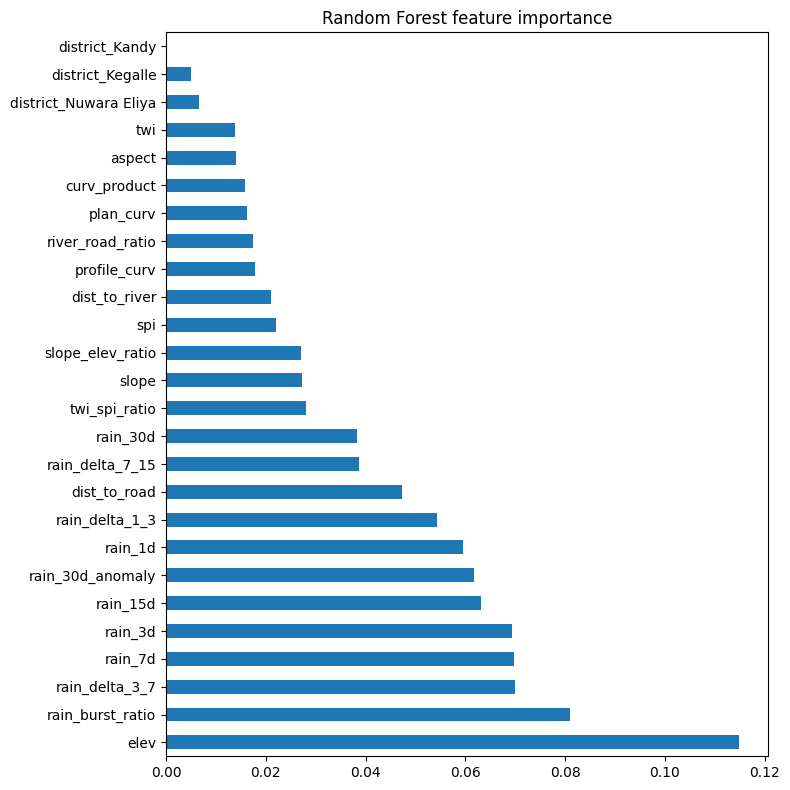

In [10]:
# --- Feature importance (Random Forest) ---
importances = pd.Series(rf.feature_importances_, index=feature_cols).sort_values(ascending=False)
importances.plot(kind="barh", figsize=(8, 8))
plt.title("Random Forest feature importance")
plt.tight_layout()
plt.show()

## 7. Diagnostics: overfitting check + Leave-One-District-Out CV
A single train/test split is a noisy sample of size 1 (only 4 districts). This section checks for RF overfitting and gets a more robust district-by-district comparison.

In [11]:
# Train vs test AUC gap for RF (overfitting check)
rf_train_auc = roc_auc_score(y_train, rf.predict_proba(X_train)[:, 1])
rf_test_auc = roc_auc_score(y_test, rf.predict_proba(X_test)[:, 1])
print(f"RF train AUC: {rf_train_auc:.3f}  |  RF test AUC: {rf_test_auc:.3f}  |  gap: {rf_train_auc - rf_test_auc:.3f}")
# A gap > ~0.15-0.20 suggests overfitting -> reduce max_depth / raise min_samples_leaf further

RF train AUC: 0.904  |  RF test AUC: 0.682  |  gap: 0.223


In [12]:
from sklearn.model_selection import LeaveOneGroupOut

logo = LeaveOneGroupOut()
rf_scores, lr_scores = [], []

for tr_idx, te_idx in logo.split(X, y, groups):
    held_out = groups.iloc[te_idx].unique()[0]

    rf_cv = RandomForestClassifier(n_estimators=300, max_depth=8, min_samples_leaf=15,
                                    random_state=42, n_jobs=-1)
    rf_cv.fit(X.iloc[tr_idx], y.iloc[tr_idx])
    rf_auc = roc_auc_score(y.iloc[te_idx], rf_cv.predict_proba(X.iloc[te_idx])[:, 1])

    sc = StandardScaler()
    Xtr, Xte = sc.fit_transform(X.iloc[tr_idx]), sc.transform(X.iloc[te_idx])
    lr_cv = LogisticRegression(max_iter=1000)
    lr_cv.fit(Xtr, y.iloc[tr_idx])
    lr_auc = roc_auc_score(y.iloc[te_idx], lr_cv.predict_proba(Xte)[:, 1])

    rf_scores.append(rf_auc)
    lr_scores.append(lr_auc)
    print(f"Held out {held_out:15s}  RF AUC: {rf_auc:.3f}   LR AUC: {lr_auc:.3f}")

print(f"\nRF mean AUC: {np.mean(rf_scores):.3f} ± {np.std(rf_scores):.3f}")
print(f"LR mean AUC: {np.mean(lr_scores):.3f} ± {np.std(lr_scores):.3f}")

Held out Badulla          RF AUC: 0.534   LR AUC: 0.616
Held out Kandy            RF AUC: 0.682   LR AUC: 0.710
Held out Kegalle          RF AUC: 0.665   LR AUC: 0.695
Held out Nuwara Eliya     RF AUC: 0.522   LR AUC: 0.493

RF mean AUC: 0.601 ± 0.073
LR mean AUC: 0.628 ± 0.086


## 8. Hybrid model: stacking ensemble (RF + XGBoost → Logistic Regression meta-learner)
Requires `xgboost` (`pip install xgboost --break-system-packages`).

In [13]:
from sklearn.ensemble import StackingClassifier
from xgboost import XGBClassifier

base_learners = [
    ("rf", RandomForestClassifier(n_estimators=300, max_depth=8, min_samples_leaf=15,
                                   random_state=42, n_jobs=-1)),
    ("xgb", XGBClassifier(n_estimators=300, max_depth=5, random_state=42, eval_metric="logloss")),
]

stack = StackingClassifier(
    estimators=base_learners,
    final_estimator=LogisticRegression(max_iter=1000),
    cv=5,
    n_jobs=-1,
)
stack.fit(X_train, y_train)

pred_stack = stack.predict(X_test)
proba_stack = stack.predict_proba(X_test)[:, 1]
print("=== Stacking hybrid (RF + XGBoost + LR meta-learner) ===")
print(classification_report(y_test, pred_stack))
print("ROC-AUC:", roc_auc_score(y_test, proba_stack))

=== Stacking hybrid (RF + XGBoost + LR meta-learner) ===
              precision    recall  f1-score   support

           0       0.64      0.54      0.59       288
           1       0.60      0.69      0.64       289

    accuracy                           0.62       577
   macro avg       0.62      0.62      0.61       577
weighted avg       0.62      0.62      0.61       577

ROC-AUC: 0.6532103037293349


## 9. Optional: Frequency Ratio transform (statistical + ML hybrid)
Converts each continuous feature into a class-based susceptibility weight before modeling — the classic NBRO-style "hybrid" approach.

In [14]:
def frequency_ratio(frame, feature, label, bins=10):
    frame = frame.copy()
    frame["_bin"] = pd.qcut(frame[feature], bins, duplicates="drop")
    total_pos_rate = frame[label].mean()
    fr_map = frame.groupby("_bin")[label].mean() / total_pos_rate
    return frame["_bin"].map(fr_map).astype(float)

fr_features = ["slope", "twi", "spi", "dist_to_river", "elev", "rain_7d", "rain_30d"]
X_fr = X_train.copy()
train_labels = eng.loc[X_train.index, "label"]
for f in fr_features:
    X_fr[f + "_fr"] = frequency_ratio(eng.loc[X_train.index], f, "label")

X_fr.filter(like="_fr").describe()

C:\Users\PCC\AppData\Local\Temp\ipykernel_6564\2114375968.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  fr_map = frame.groupby("_bin")[label].mean() / total_pos_rate
C:\Users\PCC\AppData\Local\Temp\ipykernel_6564\2114375968.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  fr_map = frame.groupby("_bin")[label].mean() / total_pos_rate
C:\Users\PCC\AppData\Local\Temp\ipykernel_6564\2114375968.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future defaul

,slope_fr,twi_fr,spi_fr,dist_to_river_fr,elev_fr,rain_7d_fr,rain_30d_fr
count,886.000000,886.000000,886.000000,886.000000,886.000000,886.000000,886.000000
mean,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
std,0.188345,0.109500,0.205496,0.113011,0.320367,0.267849,0.202542
min,0.494382,0.831461,0.516854,0.853933,0.314607,0.645833,0.666667
25%,0.977273,0.921348,0.876404,0.931818,0.818182,0.735632,0.824742
50%,1.073417,0.977528,1.078652,0.988764,1.073544,1.000000,1.068182
75%,1.101124,1.078652,1.123596,1.020833,1.123596,1.160494,1.120879
max,1.181818,1.227273,1.258427,1.250000,1.500000,1.505618,1.298701
